# 02 - Shadows rendered from predicted depth vs from LiDAR vs what the camera sees

Notebook 01 showed KITTI timestamps are local time (CEST, UTC+2): the pole shadows
match the UTC+2 sun, not UTC+0.

For a few frames:
1. predict metric depth with a small model (CPU friendly),
2. find road / sidewalk (receivers) and sky with a small segmentation model,
3. detect the real shadows on the receivers (dark asphalt vs sunlit asphalt),
4. render shadows from LiDAR depth and from predicted depth using the known sun,
5. compare each rendering with the real shadows (IoU on receivers only).

First version (v0) marked 55% of pixels as shadow, sky included. Fixes: sky is removed
from the geometry, the self-shadow tolerance grows with depth, and we only score
road / sidewalk.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import kitti
import scene
import shadows
import sun

DATE_DIR = ROOT / "data/raw/2011_09_26"
DRIVE = DATE_DIR / "2011_09_26_drive_0001_sync"
FIG = ROOT / "outputs/figures"
UTC_OFFSET = 2

torch.set_num_threads(6)
oxts = kitti.read_oxts(DRIVE)
stamps = kitti.read_timestamps(DRIVE / "oxts/timestamps.txt")
calib = kitti.read_calib(DATE_DIR)

In [2]:
MODEL_ID = "depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf"
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).eval()


@torch.no_grad()
def predict_depth(img):
    inputs = processor(images=img, return_tensors="pt")
    pred = model(**inputs).predicted_depth[:, None]
    pred = F.interpolate(pred, size=img.shape[:2], mode="bilinear", align_corners=False)
    return pred[0, 0].numpy()


def down(x, hs, ws, mode="nearest"):
    t = torch.from_numpy(np.ascontiguousarray(x)).float()[None, None]
    return F.interpolate(t, size=(hs, ws), mode=mode)[0, 0].numpy()


def abs_rel(pred, gt):
    m = gt > 0
    return float(np.mean(np.abs(pred[m] - gt[m]) / gt[m]))

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

In [3]:
SCALE = 0.25
frames = [0, 30, 60, 90]
rows = []
for i in frames:
    img = kitti.load_image(DRIVE, i)
    h, w = img.shape[:2]
    hs, ws = int(h * SCALE), int(w * SCALE)
    K = shadows.resize_K(calib["K2"], ws / w, hs / h)

    labels = scene.segment(img)
    pred = predict_depth(img)
    pred[labels == scene.SKY] = 0
    lidar = kitti.velo_to_depth(kitti.load_velo(DRIVE, i), calib, h, w)
    s_cam, az, el = sun.sun_in_camera(oxts, i, stamps[i], calib, UTC_OFFSET)

    small_img = down(img.mean(-1), hs, ws, "area")
    receiver = down(scene.receiver_mask(labels), hs, ws) > 0.5
    real = scene.observed_shadow(np.repeat(small_img[..., None], 3, -1), receiver)

    pred_s = down(pred, hs, ws)
    lidar_s = scene.densify_lidar(down(lidar, hs, ws))
    sh_pred = shadows.render_shadow(pred_s, K, s_cam)
    sh_lidar = shadows.render_shadow(lidar_s, K, s_cam)

    # only score receiver pixels that both geometries cover
    region = receiver & (lidar_s > 0) & (pred_s > 0)
    r = dict(i=i, img=img, real=real, sh_pred=sh_pred, sh_lidar=sh_lidar, region=region,
             absrel=abs_rel(pred, lidar), el=el,
             iou_lidar=scene.iou(sh_lidar, real, region), iou_pred=scene.iou(sh_pred, real, region))
    rows.append(r)
    print(f"frame {i:3d}  AbsRel {r['absrel']:.3f}  real-shadow frac {real[region].mean():.2f}  "
          f"IoU lidar {r['iou_lidar']:.2f}  IoU pred {r['iou_pred']:.2f}")

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

model.safetensors: downloading bytes:           |  0.00B            

frame   0  AbsRel 0.082  real-shadow frac 0.43  IoU lidar 0.03  IoU pred 0.13


frame  30  AbsRel 0.097  real-shadow frac 0.34  IoU lidar 0.10  IoU pred 0.10


frame  60  AbsRel 0.083  real-shadow frac 0.15  IoU lidar 0.05  IoU pred 0.30


frame  90  AbsRel 0.089  real-shadow frac 0.21  IoU lidar 0.01  IoU pred 0.06


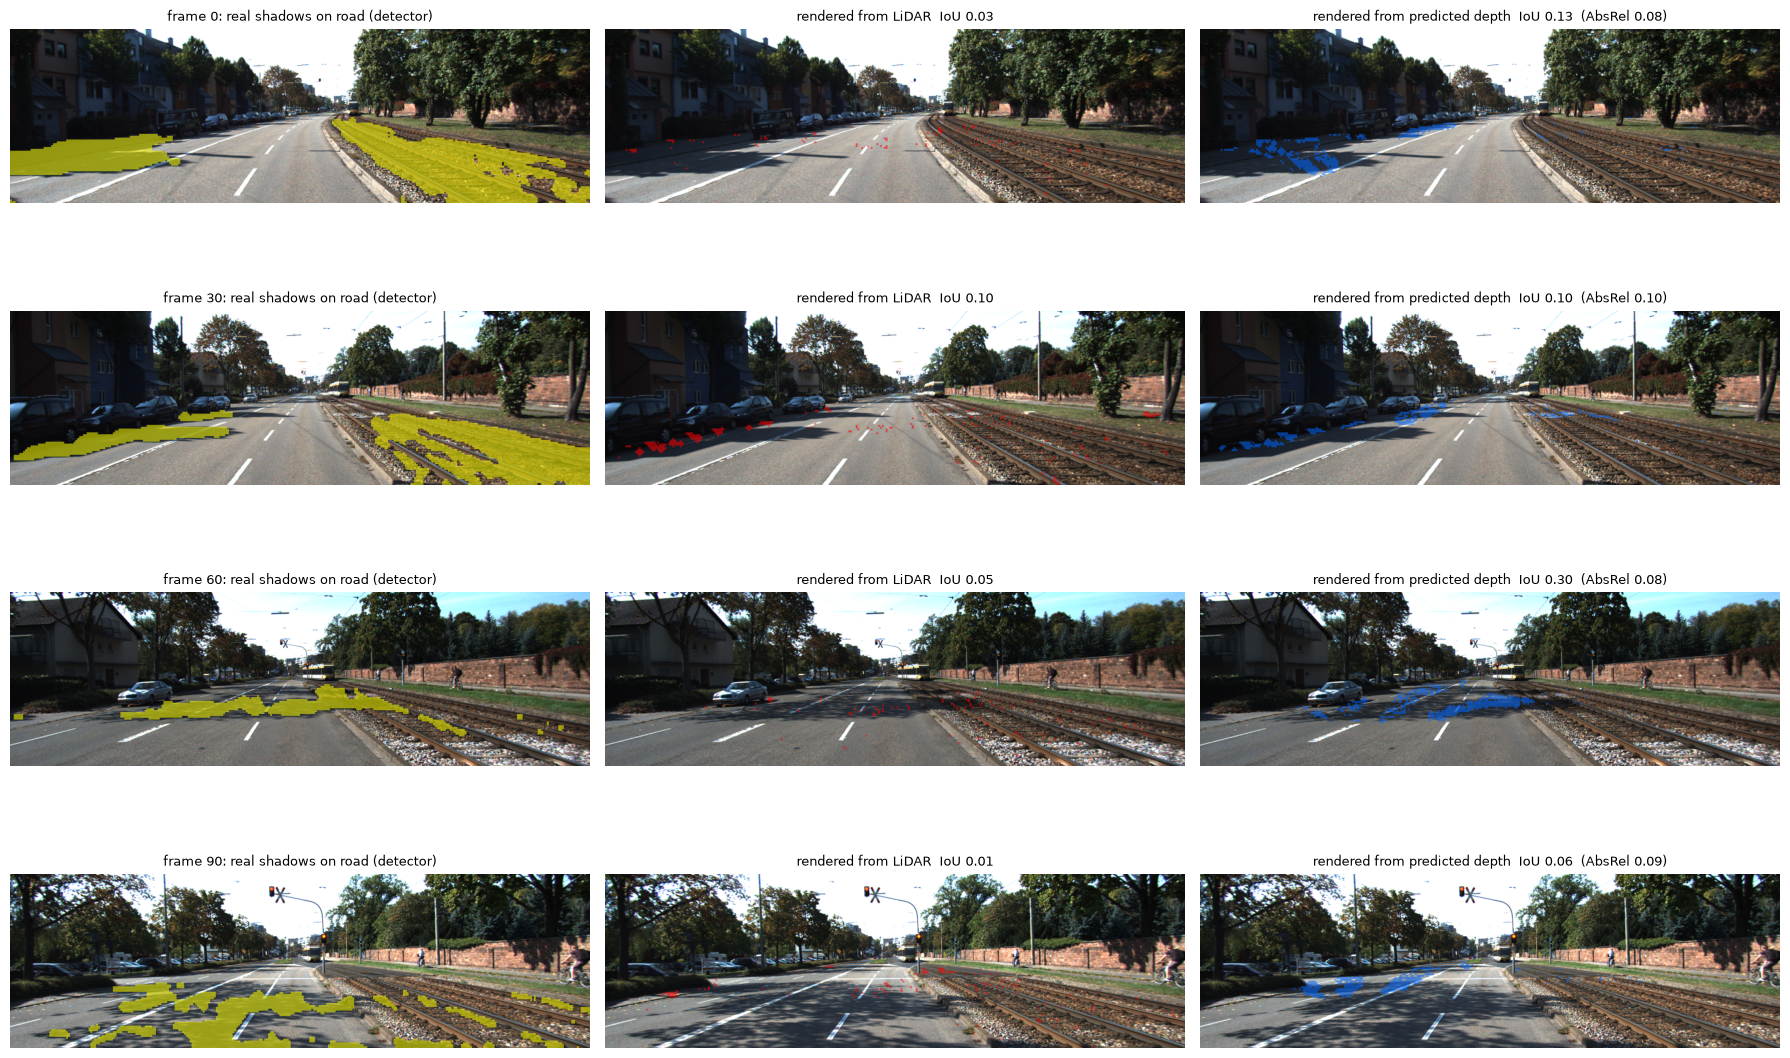

In [4]:
def overlay(ax, img, mask, color, title):
    ax.imshow(img)
    big = np.kron(mask, np.ones((4, 4), bool))[: img.shape[0], : img.shape[1]]
    rgba = np.zeros((*big.shape, 4))
    rgba[big] = (*color, 0.55)
    ax.imshow(rgba)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(len(rows), 3, figsize=(18, 3.0 * len(rows)))
for r, ax in zip(rows, axes):
    overlay(ax[0], r["img"], r["real"], (1, 1, 0), f"frame {r['i']}: real shadows on road (detector)")
    overlay(ax[1], r["img"], r["sh_lidar"] & r["region"], (1, 0, 0), f"rendered from LiDAR  IoU {r['iou_lidar']:.2f}")
    overlay(ax[2], r["img"], r["sh_pred"] & r["region"], (0, 0.4, 1),
            f"rendered from predicted depth  IoU {r['iou_pred']:.2f}  (AbsRel {r['absrel']:.2f})")
plt.tight_layout()
plt.savefig(FIG / "02_rendered_shadows.png", dpi=70)
plt.show()